## 1. Install and import dependencies
Run the installation cell only if the packages are not already installed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 3.1.1
numpy: 2.5.4


## 2. Configure multi-region input paths and target country output

Specify the list of regional CSV files for the target country (e.g. 4–5 regions) in `INPUT_CSVS`. The aggregated, weighted carbon intensity output is written to `OUTPUT_CSV`.

In [2]:
# List all regional CSV input files for the target country
INPUT_CSVS = [
    Path("../../data/SE1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv"),
    Path("../../data/SE2_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv"),
    Path("../../data/SE3_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv"),
    Path("../../data/SE4_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv"),
]

TARGET_COUNTRY_NAME = "Sweden"  # Or string code representing the target country
OUTPUT_CSV = Path("../../data/SE_generation_with_estimated_carbon_intensity.csv")

# The source data uses 15-minute intervals.
INTERVAL_HOURS = 0.25

missing_files = [p for p in INPUT_CSVS if not p.exists()]
if missing_files:
    print(f"Warning: The following input files were not found: {missing_files}")
    print("Please update INPUT_CSVS paths as needed.")
else:
    print(f"Found {len(INPUT_CSVS)} input region files.")
print("Output file:", OUTPUT_CSV.resolve())

Found 4 input region files.
Output file: C:\Games\Univer\teza_master\evaluation_of_spatio-temporal_task_scheduling\data\SE_generation_with_estimated_carbon_intensity.csv


## 3. Load, combine, and inspect the source data from all regions

In [3]:
df_list = []
required_columns = {"MTU (CET/CEST)", "Area", "Production Type", "Generation (MW)"}

for file_path in INPUT_CSVS:
    if file_path.exists():
        region_df = pd.read_csv(file_path, dtype={"Generation (MW)": "string"})
        missing_columns = required_columns - set(region_df.columns)
        if missing_columns:
            raise ValueError(f"File {file_path} is missing required columns: {sorted(missing_columns)}")
        region_df["Source_File"] = file_path.name
        df_list.append(region_df)

if df_list:
    df = pd.concat(df_list, ignore_index=True)
    print("Total Rows Loaded:", len(df))
    print("Regions / Areas found:", df["Area"].unique().tolist())
    display(df.head())
    display(df["Production Type"].value_counts(dropna=False).rename("row_count").to_frame())
else:
    print("No input data loaded. Check file paths.")

Total Rows Loaded: 2943360
Regions / Areas found: ['BZN|SE1', 'BZN|SE2', 'BZN|SE3', 'BZN|SE4']


,MTU (CET/CEST),Area,Production Type,Generation (MW),Source_File
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,BZN|SE1,Biomass,n/e,SE1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,BZN|SE1,Biomass,n/e,SE1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,BZN|SE1,Biomass,n/e,SE1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,BZN|SE1,Biomass,n/e,SE1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,BZN|SE1,Biomass,n/e,SE1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv


,row_count
Production Type,
Biomass,140160
Energy storage,140160
Fossil Brown coal/Lignite,140160
Fossil Coal-derived gas,140160
Fossil Gas,140160
Fossil Hard coal,140160
Fossil Oil,140160
Fossil Oil shale,140160
Fossil Peat,140160


## 4. Define lifecycle emission factors

Lifecycle carbon emission factors for each ENTSO-E generation production type ($gCO_2eq / kWh$).

In [4]:
EMISSION_FACTORS = {
    "Wind Onshore": 11.0,
    "Wind Offshore": 11.0,
    "Solar": 48.0,
    "Nuclear": 12.0,
    "Hydro Run-of-river and pondage": 24.0,
    "Hydro Water Reservoir": 24.0,
    "Biomass": 230.0,
    "Fossil Gas": 490.0,
    "Fossil Coal-derived gas": 490.0,
    "Fossil Brown coal/Lignite": 820.0,
    "Fossil Hard coal": 820.0,
    "Fossil Oil": 650.0,
    "Fossil Oil shale": 650.0,
    "Fossil Peat": 820.0,
    "Geothermal": 24.0,
    "Marine": 24.0,
    "Other renewable": 48.0,
    "Other": 490.0,
    "Waste": 500.0,
}

EXCLUDED_SOURCES = {
    "Energy storage",
    "Hydro Pumped Storage",
}

factor_table = (
    pd.DataFrame(
        [{"Production Type": source, "Lifecycle emission factor (gCO2eq/kWh)": factor}
         for source, factor in EMISSION_FACTORS.items()]
    )
    .sort_values("Production Type")
    .reset_index(drop=True)
)
display(factor_table)

,Production Type,Lifecycle emission factor (gCO2eq/kWh)
0,Biomass,230.0
1,Fossil Brown coal/Lignite,820.0
2,Fossil Coal-derived gas,490.0
3,Fossil Gas,490.0
4,Fossil Hard coal,820.0
5,Fossil Oil,650.0
6,Fossil Oil shale,650.0
7,Fossil Peat,820.0
8,Geothermal,24.0
9,Hydro Run-of-river and pondage,24.0


## 5. Clean generation values and parse interval timestamps

In [5]:
work = df.copy()

# Convert generation values to numeric. Invalid tokens such as "n/e" and "-" become NaN.
work["Generation (MW)"] = pd.to_numeric(
    work["Generation (MW)"].astype("string").str.strip().replace({"": pd.NA, "n/e": pd.NA, "-": pd.NA}),
    errors="coerce"
)

# Split interval strings into start and end timestamps
interval_parts = work["MTU (CET/CEST)"].astype("string").str.split(r"\s+-\s+", n=1, expand=True)
if interval_parts.shape[1] != 2:
    raise ValueError("Could not parse interval column; expected 'start - end' strings.")

work["Interval start"] = pd.to_datetime(interval_parts[0], dayfirst=True, errors="coerce")
work["Interval end"] = pd.to_datetime(interval_parts[1], dayfirst=True, errors="coerce")

work["Lifecycle emission factor (gCO2eq/kWh)"] = work["Production Type"].map(EMISSION_FACTORS)

# Mark rows included in carbon intensity calculations
work["Included in carbon-intensity calculation"] = (
    work["Lifecycle emission factor (gCO2eq/kWh)"].notna()
    & work["Generation (MW)"].notna()
)

print("Rows:", len(work))
print("Invalid/missing generation values:", int(work["Generation (MW)"].isna().sum()))
display(work.head())

Rows: 2943360
Invalid/missing generation values: 2400740


,MTU (CET/CEST),Area,Production Type,Generation (MW),Source_File,Interval start,Interval end,Lifecycle emission factor (gCO2eq/kWh),Included in carbon-intensity calculation
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,BZN|SE1,Biomass,<NA>,SE1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv,2026-01-01 00:00:00,2026-01-01 00:15:00,230.0,False
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,BZN|SE1,Biomass,<NA>,SE1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv,2026-01-01 00:15:00,2026-01-01 00:30:00,230.0,False
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,BZN|SE1,Biomass,<NA>,SE1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv,2026-01-01 00:30:00,2026-01-01 00:45:00,230.0,False
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,BZN|SE1,Biomass,<NA>,SE1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv,2026-01-01 00:45:00,2026-01-01 01:00:00,230.0,False
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,BZN|SE1,Biomass,<NA>,SE1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv,2026-01-01 01:00:00,2026-01-01 01:15:00,230.0,False


## 6. Calculate emissions per source row across all regions

In [6]:
# Generation (MW) is treated as average power over the 15-min interval.
work["Generation included (MW)"] = work["Generation (MW)"].where(
    work["Included in carbon-intensity calculation"], 0.0
)

# Single-row estimated emissions (tCO2eq per 15 min):
# tCO2eq = MW * 0.25 h * EF (gCO2eq/kWh) / 1000
work["Estimated emissions (tCO2eq per 15 min)"] = (
    work["Generation (MW)"]
    * INTERVAL_HOURS
    * work["Lifecycle emission factor (gCO2eq/kWh)"]
    / 1000.0
)
work.loc[~work["Included in carbon-intensity calculation"], "Estimated emissions (tCO2eq per 15 min)"] = np.nan

# Single-row carbon intensity (gCO2eq/kWh) - equals Lifecycle emission factor for included rows
work["Estimated carbon intensity (gCO2eq/kWh)"] = work["Lifecycle emission factor (gCO2eq/kWh)"].where(
    work["Included in carbon-intensity calculation"], np.nan
)

display(work[[
    "MTU (CET/CEST)", "Area", "Production Type", "Generation (MW)",
    "Lifecycle emission factor (gCO2eq/kWh)",
    "Estimated emissions (tCO2eq per 15 min)"
]].head(10))

,MTU (CET/CEST),Area,Production Type,Generation (MW),Lifecycle emission factor (gCO2eq/kWh),Estimated emissions (tCO2eq per 15 min)
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,BZN|SE1,Biomass,<NA>,230.0,<NA>
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,BZN|SE1,Biomass,<NA>,230.0,<NA>
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,BZN|SE1,Biomass,<NA>,230.0,<NA>
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,BZN|SE1,Biomass,<NA>,230.0,<NA>
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,BZN|SE1,Biomass,<NA>,230.0,<NA>
5,01/01/2026 01:15:00 - 01/01/2026 01:30:00,BZN|SE1,Biomass,<NA>,230.0,<NA>
6,01/01/2026 01:30:00 - 01/01/2026 01:45:00,BZN|SE1,Biomass,<NA>,230.0,<NA>
7,01/01/2026 01:45:00 - 01/01/2026 02:00:00,BZN|SE1,Biomass,<NA>,230.0,<NA>
8,01/01/2026 02:00:00 - 01/01/2026 02:15:00,BZN|SE1,Biomass,<NA>,230.0,<NA>
9,01/01/2026 02:15:00 - 01/01/2026 02:30:00,BZN|SE1,Biomass,<NA>,230.0,<NA>


In [7]:
# Weighted numerator for each row
work["Weighted generation x factor"] = (
    work["Generation included (MW)"]
    * work["Lifecycle emission factor (gCO2eq/kWh)"].fillna(0.0)
)

# Group solely by MTU (UTC) timestamp to merge all regions of the target country
COUNTRY_GROUP_KEYS = ["MTU (CET/CEST)"]

interval_summary = (
    work.groupby(COUNTRY_GROUP_KEYS, dropna=False)
    .agg(
        **{
            "Target Country Total Generation Included (MW)": ("Generation included (MW)", "sum"),
            "Weighted generation x factor": ("Weighted generation x factor", "sum"),
            "Target Country Total Emissions (tCO2eq per 15 min)": (
                "Estimated emissions (tCO2eq per 15 min)",
                lambda s: s.sum(min_count=1)
            ),
            "Interval start": ("Interval start", "min"),
            "Interval end": ("Interval end", "max"),
        }
    )
    .reset_index()
)

interval_summary["Target Country Carbon Intensity (gCO2eq/kWh)"] = np.where(
    interval_summary["Target Country Total Generation Included (MW)"] > 0,
    interval_summary["Weighted generation x factor"]
        / interval_summary["Target Country Total Generation Included (MW)"],
    np.nan
)

interval_summary = interval_summary.drop(columns=["Weighted generation x factor"])

print("Total Intervals:", len(interval_summary))
display(interval_summary.head())

Total Intervals: 35040


,MTU (CET/CEST),Target Country Total Generation Included (MW),Target Country Total Emissions (tCO2eq per 15 min),Interval start,Interval end,Target Country Carbon Intensity (gCO2eq/kWh)
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,23903.33,194.052183,2026-01-01 00:00:00,2026-01-01 00:15:00,32.472828
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,24021.97,196.555073,2026-01-01 00:15:00,2026-01-01 00:30:00,32.729218
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,23928.02,194.87406,2026-01-01 00:30:00,2026-01-01 00:45:00,32.576713
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,24011.98,193.390538,2026-01-01 00:45:00,2026-01-01 01:00:00,32.215675
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,23885.8,192.205175,2026-01-01 01:00:00,2026-01-01 01:15:00,32.187354


## 8. Join target country average CI back to regional rows and export

In [8]:
# Prepare interval-level target country aggregated metrics
metrics = interval_summary[COUNTRY_GROUP_KEYS + [
    "Target Country Carbon Intensity (gCO2eq/kWh)",
    "Target Country Total Generation Included (MW)",
    "Target Country Total Emissions (tCO2eq per 15 min)"
]].rename(columns={
    "Target Country Carbon Intensity (gCO2eq/kWh)": "Estimated total carbon intensity (gCO2eq/kWh)", # optional helper
    "Target Country Total Generation Included (MW)": "Total generation included (MW)",
    "Target Country Total Emissions (tCO2eq per 15 min)": "Estimated total emissions (tCO2eq per 15 min)"
})

# Merge interval metrics back to regional rows
work = work.merge(metrics, on=COUNTRY_GROUP_KEYS, how="left")

# Define the exact 9 columns in the requested order
final_output_columns = [
    "MTU (CET/CEST)",
    "Area",
    "Production Type",
    "Generation (MW)",
    "Lifecycle emission factor (gCO2eq/kWh)",
    "Estimated emissions (tCO2eq per 15 min)",
    "Estimated carbon intensity (gCO2eq/kWh)",
    "Total generation included (MW)",
    "Estimated total emissions (tCO2eq per 15 min)"
]

result = work[final_output_columns].copy()

# Save to CSV
result.to_csv(OUTPUT_CSV, index=False)
print(f"Saved {len(result):,} rows to: {OUTPUT_CSV.resolve()}")
display(result.head())

Saved 2,943,360 rows to: C:\Games\Univer\teza_master\evaluation_of_spatio-temporal_task_scheduling\data\SE_generation_with_estimated_carbon_intensity.csv


,MTU (CET/CEST),Area,Production Type,Generation (MW),Lifecycle emission factor (gCO2eq/kWh),Estimated emissions (tCO2eq per 15 min),Estimated carbon intensity (gCO2eq/kWh),Total generation included (MW),Estimated total emissions (tCO2eq per 15 min)
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,BZN|SE1,Biomass,<NA>,230.0,<NA>,NaN,23903.33,194.052183
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,BZN|SE1,Biomass,<NA>,230.0,<NA>,NaN,24021.97,196.555073
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,BZN|SE1,Biomass,<NA>,230.0,<NA>,NaN,23928.02,194.87406
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,BZN|SE1,Biomass,<NA>,230.0,<NA>,NaN,24011.98,193.390538
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,BZN|SE1,Biomass,<NA>,230.0,<NA>,NaN,23885.8,192.205175


## 9. Validation checks

## 7. Aggregate generation and compute target country average CI per interval

To calculate the country-wide carbon intensity across multiple regional CSV inputs, we aggregate all regional power generation and emissions by interval (`MTU (UTC)` or `Interval start`).

$$\text{Target Country CI}(t) = \frac{\sum_{\text{regions}} \sum_{\text{sources}} \text{Generation}_{r,s}(t) \times \text{EF}_s}{\sum_{\text{regions}} \sum_{\text{sources}} \text{Generation}_{r,s}(t)}$$

In [9]:
# 1) Check carbon intensity bounds
known_factors = list(EMISSION_FACTORS.values())
ci = interval_summary["Target Country Carbon Intensity (gCO2eq/kWh)"].dropna()
assert ci.empty or (ci.min() >= min(known_factors) - 1e-9)
assert ci.empty or (ci.max() <= max(known_factors) + 1e-9)

# 2) Check that interval_summary itself has unique intensities per interval (if evaluated per interval)
distinct_ci = interval_summary.groupby("MTU (CET/CEST)")["Target Country Carbon Intensity (gCO2eq/kWh)"].nunique(dropna=True)
assert (distinct_ci <= 1).all()

print("All validation assertions passed.")
print(f"Target Country Intervals: {len(interval_summary):,}")
if not ci.empty:
    print(f"Carbon Intensity Min: {ci.min():.2f} gCO2eq/kWh")
    print(f"Carbon Intensity Median: {ci.median():.2f} gCO2eq/kWh")
    print(f"Carbon Intensity Max: {ci.max():.2f} gCO2eq/kWh")

All validation assertions passed.
Target Country Intervals: 35,040
Carbon Intensity Min: 23.22 gCO2eq/kWh
Carbon Intensity Median: 37.16 gCO2eq/kWh
Carbon Intensity Max: 67.86 gCO2eq/kWh


## 10. Descriptive statistics and regional/source contributions

In [10]:
display(interval_summary["Target Country Carbon Intensity (gCO2eq/kWh)"].describe().to_frame())

# Aggregate total generation and emissions by Production Type across all regions
source_summary = (
    work.groupby("Production Type", dropna=False)
    .agg(
        rows=("Production Type", "size"),
        valid_generation_rows=("Generation (MW)", "count"),
        total_generation_MWh=("Generation included (MW)", lambda s: s.sum() * INTERVAL_HOURS),
        estimated_emissions_tCO2eq=("Estimated emissions (tCO2eq per 15 min)", lambda s: s.sum(min_count=1)),
        emission_factor_gCO2eq_kWh=("Lifecycle emission factor (gCO2eq/kWh)", "first")
    )
    .sort_values("total_generation_MWh", ascending=False)
)
display(source_summary)

,Target Country Carbon Intensity (gCO2eq/kWh)
count,27131.000000
mean,38.371941
std,7.341659
min,23.216552
25%,32.787185
50%,37.163667
75%,43.571032
max,67.860289


,rows,valid_generation_rows,total_generation_MWh,estimated_emissions_tCO2eq,emission_factor_gCO2eq_kWh
Production Type,,,,,
Hydro Water Reservoir,140160,108524,48680680.115,1168336.32276,24.0
Nuclear,140160,27131,30209582.45,362514.9894,12.0
Wind Onshore,140160,108524,29929826.48,329228.09128,11.0
Other,140160,108524,5249690.8525,2572348.517725,490.0
Solar,140160,108524,2740116.4225,131525.58828,48.0
Fossil Gas,140160,81393,37733.66,18489.4934,490.0
Fossil Brown coal/Lignite,140160,0,0.0,<NA>,820.0
Energy storage,140160,0,0.0,<NA>,NaN
Biomass,140160,0,0.0,<NA>,230.0


In [11]:
display(interval_summary["Target Country Carbon Intensity (gCO2eq/kWh)"].describe().to_frame())

# Aggregate total generation and emissions by Production Type across all regions
source_summary = (
    work.groupby("Production Type", dropna=False)
    .agg(
        rows=("Production Type", "size"),
        valid_generation_rows=("Generation (MW)", "count"),
        total_generation_MWh=("Generation included (MW)", lambda s: s.sum() * INTERVAL_HOURS),
        estimated_emissions_tCO2eq=("Estimated emissions (tCO2eq per 15 min)", lambda s: s.sum(min_count=1)),
        emission_factor_gCO2eq_kWh=("Lifecycle emission factor (gCO2eq/kWh)", "first")
    )
    .sort_values("total_generation_MWh", ascending=False)
)
display(source_summary)

,Target Country Carbon Intensity (gCO2eq/kWh)
count,27131.000000
mean,38.371941
std,7.341659
min,23.216552
25%,32.787185
50%,37.163667
75%,43.571032
max,67.860289


,rows,valid_generation_rows,total_generation_MWh,estimated_emissions_tCO2eq,emission_factor_gCO2eq_kWh
Production Type,,,,,
Hydro Water Reservoir,140160,108524,48680680.115,1168336.32276,24.0
Nuclear,140160,27131,30209582.45,362514.9894,12.0
Wind Onshore,140160,108524,29929826.48,329228.09128,11.0
Other,140160,108524,5249690.8525,2572348.517725,490.0
Solar,140160,108524,2740116.4225,131525.58828,48.0
Fossil Gas,140160,81393,37733.66,18489.4934,490.0
Fossil Brown coal/Lignite,140160,0,0.0,<NA>,820.0
Energy storage,140160,0,0.0,<NA>,NaN
Biomass,140160,0,0.0,<NA>,230.0


## 11. Plot the estimated target country carbon intensity over time

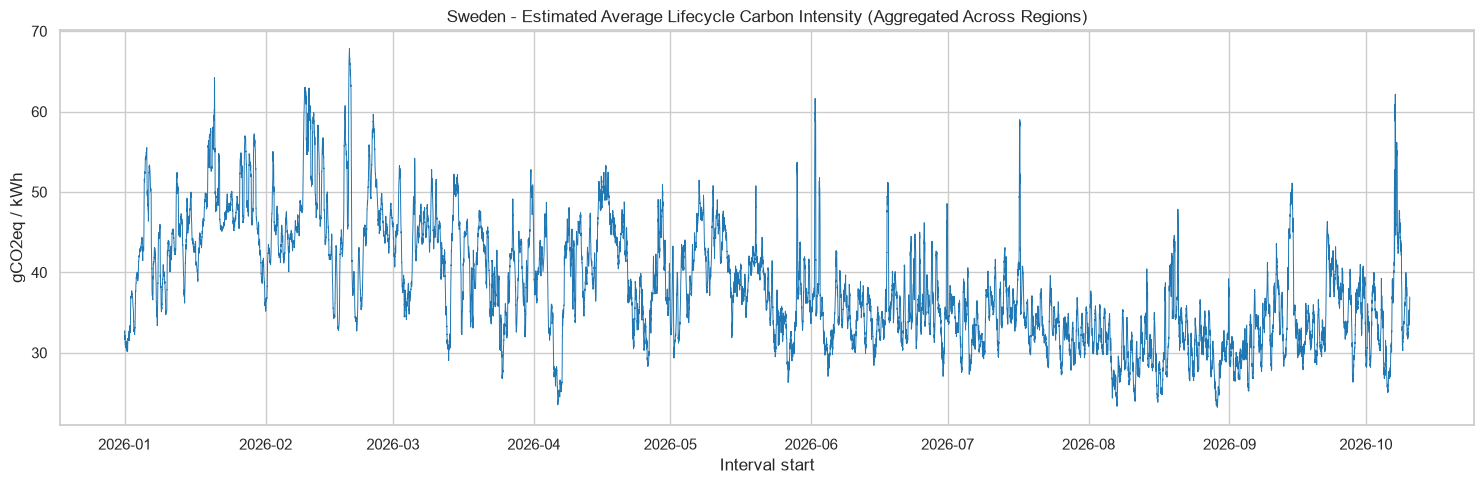

In [12]:
plot_data = interval_summary.dropna(subset=["Interval start", "Target Country Carbon Intensity (gCO2eq/kWh)"]).sort_values("Interval start")

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    plot_data["Interval start"],
    plot_data["Target Country Carbon Intensity (gCO2eq/kWh)"],
    linewidth=0.7,
    color="tab:blue"
)
ax.set_title(f"{TARGET_COUNTRY_NAME} - Estimated Average Lifecycle Carbon Intensity (Aggregated Across Regions)")
ax.set_xlabel("Interval start")
ax.set_ylabel("gCO2eq / kWh")
fig.tight_layout()
plt.show()